# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [3]:
%pip install torch torchvision

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 7.3 MB/s  0:00:19 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 22.0 MB/s  0:00:00
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [torchvision] 6/7 [torchvision]]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

In [2]:
import sys
print(sys.executable)

/opt/anaconda3/envs/mt_lab/bin/python


## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

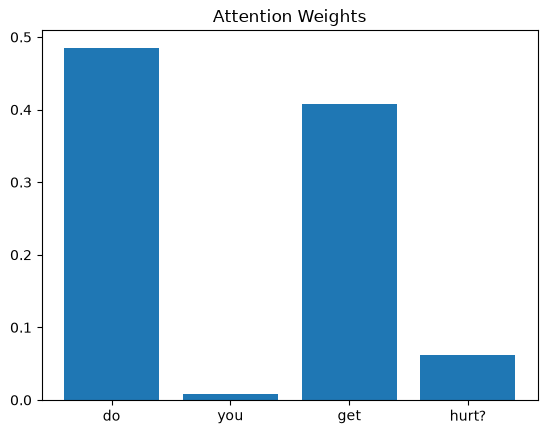

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

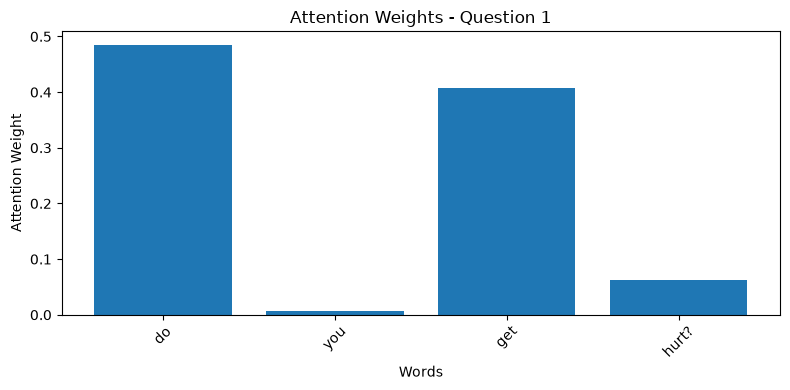

Question 1: do you get hurt?
Highest attention word: do



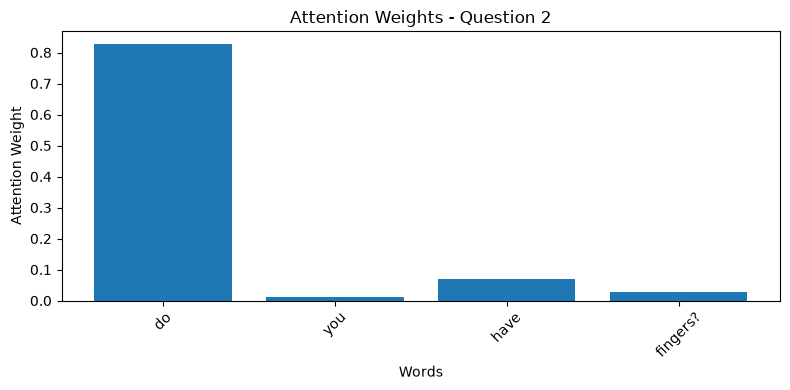

Question 2: do you have fingers?
Highest attention word: do



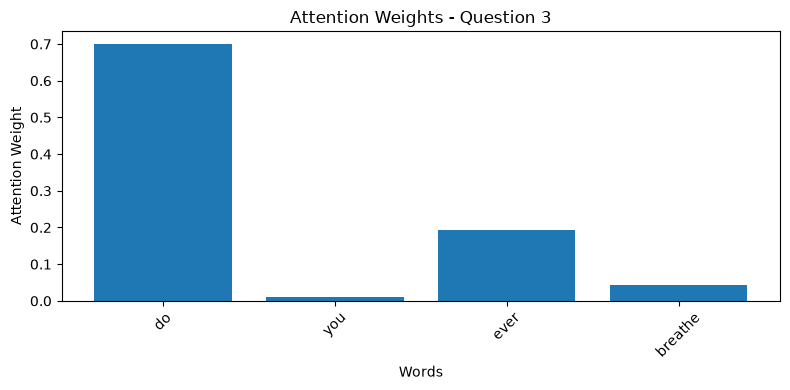

Question 3: do you ever breathe
Highest attention word: do



In [8]:
for i in range(3):
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    highest_word = words[attention_weights.index(max(attention_weights))]
    print(f"Question {i+1}: {question}")
    print(f"Highest attention word: {highest_word}\n")

The words with the highest attention weights generally appear important for understanding the question. The model assigns higher weights to words that contribute more to its prediction.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

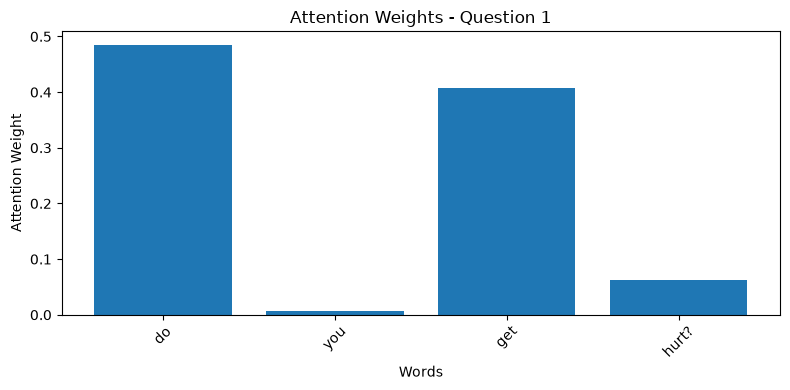

Question: do you get hurt?
Highest attention word: do



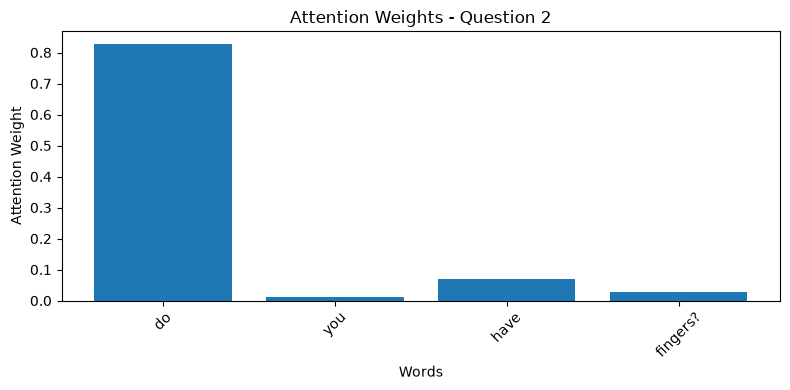

Question: do you have fingers?
Highest attention word: do



In [9]:
# Select two questions with the same answer_id
pair = df[df.duplicated("answer_id", keep=False)].groupby(
    "answer_id"
).head(2)

q1_idx = pair.index[0]
q2_idx = pair.index[1]

questions = [df.loc[q1_idx, "question"], df.loc[q2_idx, "question"]]
indices = [df.index.get_loc(q1_idx), df.index.get_loc(q2_idx)]

for i, question in enumerate(questions):
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[indices[i]:indices[i]+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    highest_word = words[attention_weights.index(max(attention_weights))]
    print(f"Question: {question}")
    print(f"Highest attention word: {highest_word}\n")

The model may focus on similar or different words when processing questions with similar meanings. This suggests that attention assigns weights to words based on their relevance to the prediction, rather than treating all words equally.